# コードの目的
ノード数に対する最適なバックオフ時間を見つける。ただし、バックオフ時間は2**N[TU]であるため、厳密な最適なバックオフ時間ではありません。

# 1.必要なライブラリ

In [3]:
from pathlib import Path
import re
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

## 2. PDFの出力先設定

ログの入力先と、生成するPDFの保存先を設定します。必要に応じてこのセルだけ編集してください。

In [ ]:
LOG_DIR = Path("tsv/optimal_backoff_20260428")

# PDF出力先
OUTPUT_DIR = Path("img/takahashi")
# COLLISION_RATE_PDF = OUTPUT_DIR / "collision_rate_comparison_optimal_backoff.pdf"
# THROUGHPUT_PER_NODE_BPS_PDF = OUTPUT_DIR / "throughput_per_node_bps_comparison_optimal_backoff.pdf"
COMPARISON_PDF = OUTPUT_DIR / "optimal_backoff_collision_rate_comparison.pdf"

# 3. 解析コード
各ノード数でTagあたりのスループットが最大となるバックオフ時間をプロットするコードです。必要に応じて編集してください。

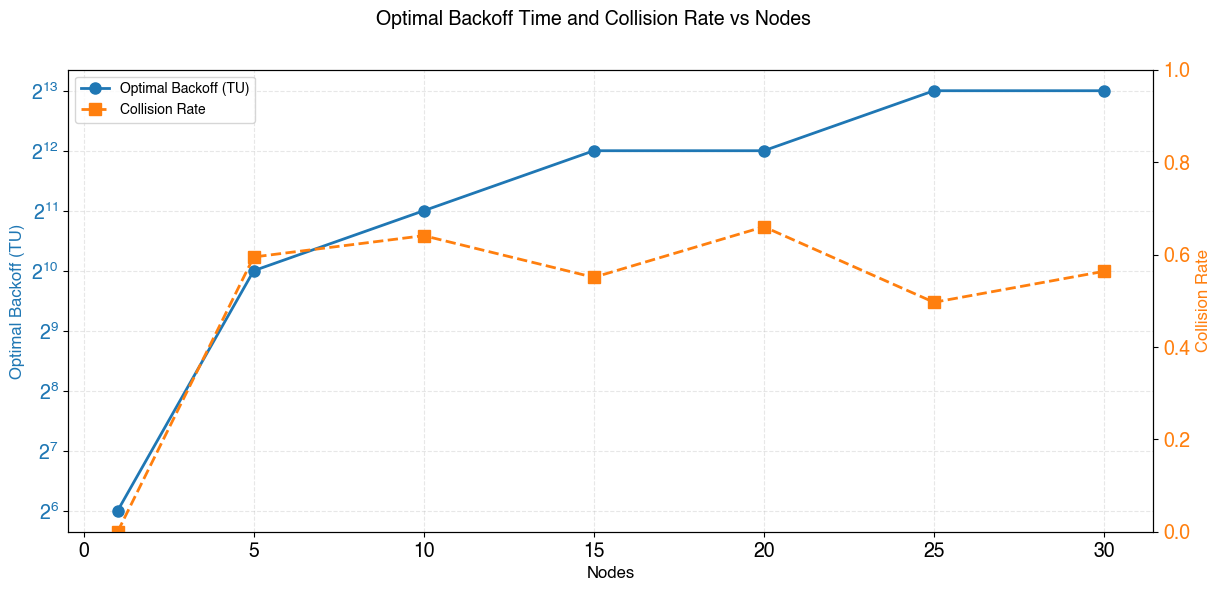

Best backoff per node (nodes, backoff, collision_rate, throughput_per_tag_bps):
 nodes  backoff  collision_rate  throughput_per_tag_bps
     1       64        0.000000            15172.755600
     5     1024        0.594660             1301.265307
    10     2048        0.640840              589.139608
    15     4096        0.550580              377.825798
    20     4096        0.660130              280.945356
    25     8192        0.496608              211.585502
    30     8192        0.563617              181.979308


In [13]:
# ノード／バックオフの期待値（必要に応じて編集）
nodes = [1, 5, 10, 15, 20, 25, 30]
backoffs = [64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384]


def load_events(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep='\t')
    df['time_tu'] = pd.to_numeric(df['time_tu'], errors='coerce')
    df['round'] = pd.to_numeric(df['round'], errors='coerce').astype('Int64')
    df['event'] = df['event'].astype(str)
    df['result'] = df['result'].astype(str)
    return df


def load_config(path: Path) -> dict:
    if not path.exists():
        return {}
    with path.open('r', encoding='utf-8') as f:
        return yaml.safe_load(f)


rows = []
LOG_DIR = Path(LOG_DIR)
if not LOG_DIR.exists():
    raise FileNotFoundError(f'LOG_DIR not found: {LOG_DIR}')

for n in nodes:
    node_dir = LOG_DIR / f'node_{n}'
    if not node_dir.exists():
        print('missing', node_dir)
        continue

    cfg = load_config(node_dir / 'config.yaml') or load_config(LOG_DIR / 'config.yaml')
    data_bits = float(cfg.get('data_bits', 128))
    tu_sec = float(cfg.get('tu', 0.0001))

    for path in sorted(node_dir.glob('*_*tsv')):
        m = re.search(r'_(\d+)\.tsv$', path.name)
        if not m:
            continue
        b = int(m.group(1))
        if b not in backoffs:
            continue

        events = load_events(path)
        if events.empty:
            continue

        success_mask = events['event'] == 'rx_success'
        successes = int(success_mask.sum())

        collisions = int((events['event'] == 'collision').sum())
        total_attempts = int((events['event'] == 'tx_preamble').sum())
        collision_rate = (collisions / total_attempts) if total_attempts > 0 else 0.0

        round_last = events.groupby('round')['time_tu'].max()
        num_rounds = int(round_last.shape[0]) if round_last.shape[0] > 0 else 0
        avg_round_tu = float(round_last.mean()) if num_rounds > 0 else 0.0
        avg_round_sec = avg_round_tu * tu_sec if avg_round_tu > 0 else 0.0
        avg_successes_per_round = (successes / num_rounds) if num_rounds > 0 else 0.0

        throughput_bps = (avg_successes_per_round * data_bits / avg_round_sec) if avg_round_sec > 0 else 0.0
        throughput_per_tag_bps = (throughput_bps / n) if n > 0 else 0.0

        rows.append({
            'nodes': n,
            'backoff': b,
            'collision_rate': collision_rate,
            'throughput_per_tag_bps': throughput_per_tag_bps,
        })


df = pd.DataFrame(rows)
if df.empty:
    raise RuntimeError('No event files processed; check LOG_DIR and naming patterns')

best = df.loc[df.groupby('nodes')['throughput_per_tag_bps'].idxmax()].sort_values('nodes')

fig, ax1 = plt.subplots(figsize=(14, 6))

# 左軸: 最適バックオフ
color_backoff = '#1f77b4'
ax1.plot(
    best['nodes'],
    best['backoff'],
    marker='o',
    label='Optimal Backoff (TU)',
    color=color_backoff,
    linestyle='-',
    linewidth=2,
    markersize=8,
)
ax1.set_xlabel('Nodes', fontsize=12)
ax1.set_ylabel('Optimal Backoff (TU)', fontsize=12, color=color_backoff)
ax1.set_yscale('log', base=2)
ax1.tick_params(axis='y', labelcolor=color_backoff)
ax1.grid(alpha=0.3, linestyle='--')

# 右軸: 衝突率
ax2 = ax1.twinx()
color_collision = '#ff7f0e'
ax2.plot(
    best['nodes'],
    best['collision_rate'],
    marker='s',
    label='Collision Rate',
    color=color_collision,
    linestyle='--',
    linewidth=2,
    markersize=8,
)
ax2.set_ylabel('Collision Rate', fontsize=12, color=color_collision)
ax2.set_ylim(0.0, 1.0)
ax2.tick_params(axis='y', labelcolor=color_collision)

fig.suptitle('Optimal Backoff Time and Collision Rate vs Nodes', fontsize=14, fontweight='bold')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best', fontsize=10)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with PdfPages(COMPARISON_PDF) as pdf:
    pdf.savefig(fig, bbox_inches='tight')
plt.show()

print('Best backoff per node (nodes, backoff, collision_rate, throughput_per_tag_bps):')
print(best[['nodes', 'backoff', 'collision_rate', 'throughput_per_tag_bps']].to_string(index=False))